# Unit 5 — Object Recognition and Motion Estimation (Task 3 and Task 4)

**Part 1 – Task 3: Object recognition**
Detect objects in your photo and in frames from your video with two methods and compare them:
* **Viola–Jones** (pretrained Haar cascade face detector, OpenCV)
* **YOLO** (pretrained YOLOv8-nano model, Ultralytics)

**Part 2 – Task 4: Motion estimation** on your video:
* frame differencing
* GMM background subtraction (MOG2)
* Lucas–Kanade optical flow

**Input:** `data/photo1.jpeg` and `data/video.mp4` (your own 15–30 second video with a moving person or object).

**Output:** every result image is saved in `outputs/unit5/`.

> The first time you run the YOLO cell, Ultralytics downloads the small pretrained model file `yolov8n.pt` (about 6 MB), so you need internet once.

In [5]:
%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python
%pip install "opencv-python<5"

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Note: you may need to restart the kernel to use updated packages.


ERROR: Exception:
Traceback (most recent call last):
  File "C:\Users\vrush\AppData\Local\Programs\Python\Python311\Lib\site-packages\pip\_internal\cli\base_command.py", line 160, in exc_logging_wrapper
    status = run_func(*args)
             ^^^^^^^^^^^^^^^
  File "C:\Users\vrush\AppData\Local\Programs\Python\Python311\Lib\site-packages\pip\_internal\commands\uninstall.py", line 103, in run
    uninstall_pathset.commit()
  File "C:\Users\vrush\AppData\Local\Programs\Python\Python311\Lib\site-packages\pip\_internal\req\req_uninstall.py", line 424, in commit
    self._moved_paths.commit()
  File "C:\Users\vrush\AppData\Local\Programs\Python\Python311\Lib\site-packages\pip\_internal\req\req_uninstall.py", line 277, in commit
    save_dir.cleanup()
  File "C:\Users\vrush\AppData\Local\Programs\Python\Python311\Lib\site-packages\pip\_internal\utils\temp_dir.py", line 173, in cleanup
    rmtree(self._path)
  File "C:\Users\vrush\AppData\Local\Programs\Python\Python311\Lib\site-packages\pi

     ---------------------------------------- 41.2/41.2 MB 1.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

OUT = "outputs/unit5"
os.makedirs(OUT, exist_ok=True)

PHOTO_PATH = "data/photo5.jpeg"
VIDEO_PATH = "data/video.mp4"


def resize(img, max_side=800):
    # Shrink so that the longer side is at most max_side pixels (works for portrait and landscape)
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    if scale < 1:
        img = cv2.resize(img, (int(w * scale), int(h * scale)))
    return img


def show(images, titles, cols=2):
    # Show many images in a grid. OpenCV stores colour as BGR, matplotlib wants RGB.
    rows = (len(images) + cols - 1) // cols
    plt.figure(figsize=(7 * cols, 5 * rows))
    for i in range(len(images)):
        plt.subplot(rows, cols, i + 1)
        if images[i].ndim == 2:
            plt.imshow(images[i], cmap="gray")
        else:
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        plt.title(titles[i])
        plt.axis("off")
    plt.tight_layout()
    plt.show()


def save(name, img):
    cv2.imwrite(os.path.join(OUT, name), img)

---
# Part 1 — Task 3: Object Recognition (Viola–Jones vs YOLO)

## Inputs: the photo + 3 frames from the video

We take frames at 25%, 50% and 75% of the video, so we test different moments.

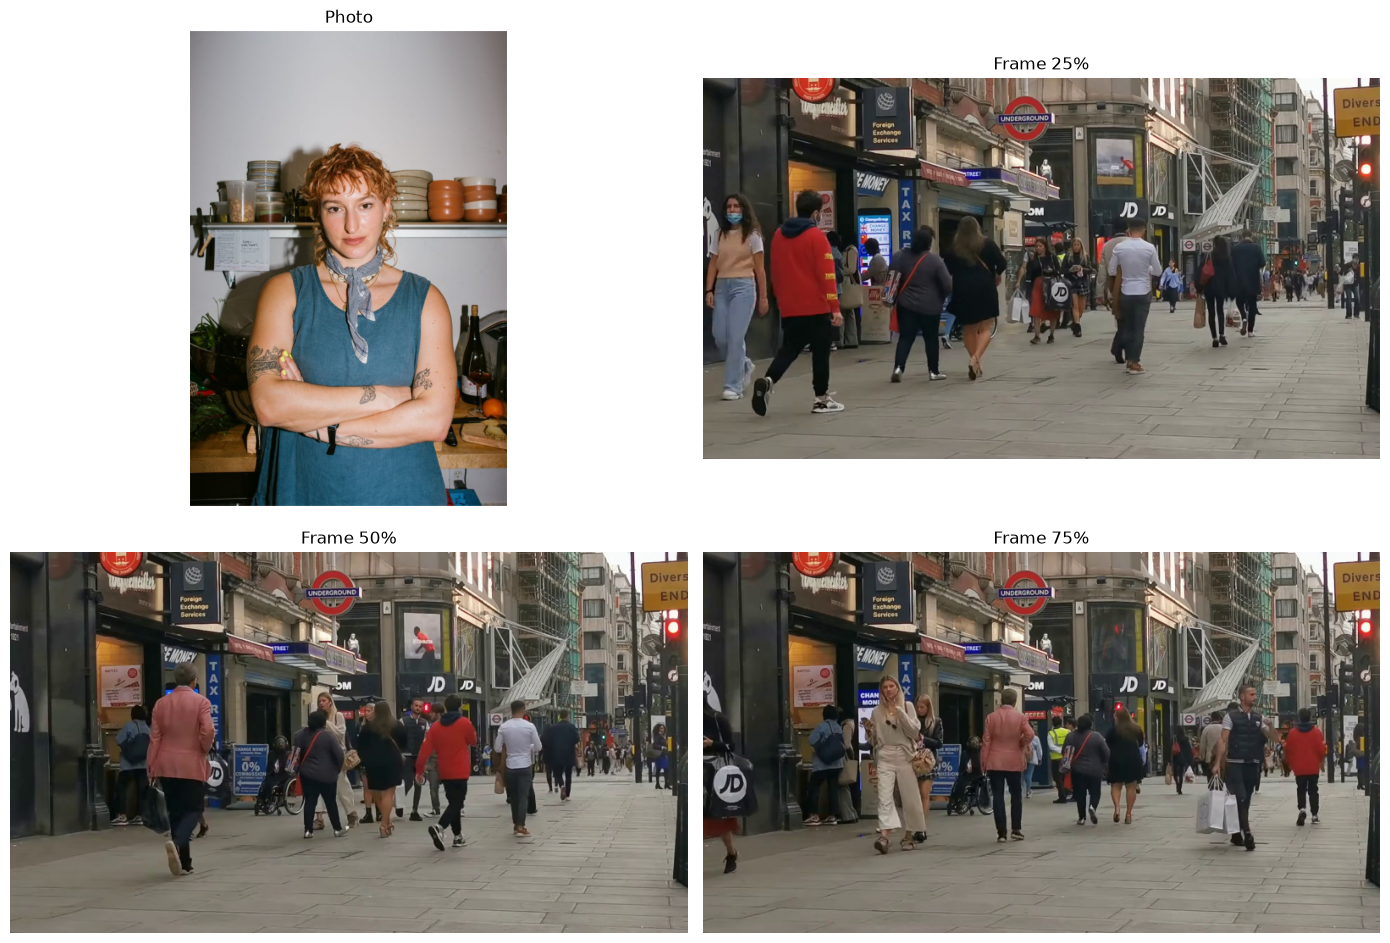

In [2]:
def read_frame(video_path, frame_number):
    # Jump to one frame of the video and read it
    cap = cv2.VideoCapture(video_path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise ValueError(f"Could not read frame {frame_number} from {video_path}")
    return resize(frame)


cap = cv2.VideoCapture(VIDEO_PATH)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
if total_frames == 0:
    raise FileNotFoundError(f"Could not read {VIDEO_PATH}. Put your video in the data folder.")

photo = cv2.imread(PHOTO_PATH)
if photo is None:
    raise FileNotFoundError(f"Could not read {PHOTO_PATH}. Put your photo in the data folder.")

test_images = {
    "Photo":     resize(photo),
    "Frame 25%": read_frame(VIDEO_PATH, total_frames // 4),
    "Frame 50%": read_frame(VIDEO_PATH, total_frames // 2),
    "Frame 75%": read_frame(VIDEO_PATH, 3 * total_frames // 4),
}

show(list(test_images.values()), list(test_images.keys()))
for name, img in test_images.items():
    save(f"00_input_{name.replace(' ', '_').replace('%', '')}.jpg", img)

## Viola–Jones face detector (Haar cascade)

OpenCV ships with ready-made (**pretrained**) Haar cascade files. We use `haarcascade_frontalface_default.xml`, which detects **front-facing faces**.

How it works in one line: it slides a window over the image at many sizes and checks simple black-and-white rectangle patterns (**Haar features**, e.g. "the eye region is darker than the cheeks") through a **cascade** of quick tests. Most windows fail the first test, so it is very fast.

Main settings of `detectMultiScale`:
* `scaleFactor=1.1` – shrink the image by 10% each step, to find faces of different sizes,
* `minNeighbors=5` – a face must be found by at least 5 overlapping windows (higher = fewer false detections),
* `minSize=(30, 30)` – ignore anything smaller than 30 × 30 pixels.

Haar cascades only answer **yes / no** – they do **not** give a confidence score.

In [3]:
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")


def detect_haar(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
    out = img.copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(out, "face", (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    return faces, out

AttributeError: module 'cv2' has no attribute 'CascadeClassifier'

## YOLO object detector

**YOLO (You Only Look Once)** is a deep-learning model. It looks at the whole image **once** and directly predicts boxes, class names and a **confidence score** (0 to 1) for every object.

We use `yolov8n.pt` – the *nano* (smallest and fastest) YOLOv8 model, pretrained on the **COCO** dataset, so it already knows **80 classes** (person, car, dog, chair, bottle, cell phone, laptop …).

`conf=0.25` → only keep detections with confidence of at least 25%.
`result.plot()` draws the boxes, labels and confidence scores for us.

In [ ]:
model = YOLO("yolov8n.pt")      # downloads automatically the first time


def detect_yolo(img):
    result = model(img, conf=0.25, verbose=False)[0]
    detections = []
    for box in result.boxes:
        name = model.names[int(box.cls[0])]     # class number -> class name
        conf = float(box.conf[0])               # confidence score
        detections.append((name, conf))
    return detections, result.plot()            # result.plot() = image with boxes drawn


_ = model(test_images["Photo"], verbose=False)  # warm-up runs: the very first call of each detector
_ = detect_haar(test_images["Photo"])           # is slow (setup), so this makes the timing fair
print("YOLO knows", len(model.names), "classes, for example:", list(model.names.values())[:10])

## Run both detectors on every image

We also measure the time each detector takes (in milliseconds) on this computer.

In [ ]:
rows = []
for name, img in test_images.items():
    start = time.perf_counter()
    faces, haar_img = detect_haar(img)
    haar_ms = (time.perf_counter() - start) * 1000

    start = time.perf_counter()
    detections, yolo_img = detect_yolo(img)
    yolo_ms = (time.perf_counter() - start) * 1000

    show([haar_img, yolo_img], [f"{name} – Haar: {len(faces)} face(s)", f"{name} – YOLO: {len(detections)} object(s)"])
    file_name = name.replace(" ", "_").replace("%", "")
    save(f"01_haar_{file_name}.jpg", haar_img)
    save(f"01_yolo_{file_name}.jpg", yolo_img)

    yolo_text = ", ".join(f"{n} ({c:.2f})" for n, c in detections) or "none"
    rows.append((name, len(faces), haar_ms, yolo_text, yolo_ms))

print("| Image | Haar: faces found | Haar time (ms) | YOLO: objects (confidence) | YOLO time (ms) |")
print("|---|---|---|---|---|")
for name, n_faces, haar_ms, yolo_text, yolo_ms in rows:
    print(f"| {name} | {n_faces} | {haar_ms:.1f} | {yolo_text} | {yolo_ms:.1f} |")

## Failure-case experiments

To find cases where a detector **misses** an object or makes a **wrong** detection, we change one image on purpose:

* **Rotated 90°** – Haar was trained only on upright faces, so it usually misses a sideways face.
* **Very dark** (25% brightness) – simulates a badly lit room.
* **Very small** (longest side 200 px) – simulates a person far away from the camera.

Change `TEST` to the name of an image that clearly shows a face.

In [ ]:
TEST = "Photo"          # "Photo", "Frame 25%", "Frame 50%" or "Frame 75%"
base = test_images[TEST]

hard_cases = {
    "Rotated 90°": cv2.rotate(base, cv2.ROTATE_90_CLOCKWISE),
    "Very dark":   (base * 0.25).astype(np.uint8),
    "Very small":  resize(base, 200),
}

print("| Test | Haar: faces found | YOLO: objects (confidence) |")
print("|---|---|---|")
for name, img in hard_cases.items():
    faces, haar_img = detect_haar(img)
    detections, yolo_img = detect_yolo(img)
    show([haar_img, yolo_img], [f"{name} – Haar: {len(faces)} face(s)", f"{name} – YOLO: {len(detections)} object(s)"])
    file_name = name.replace(" ", "_").replace("°", "")
    save(f"02_fail_haar_{file_name}.jpg", haar_img)
    save(f"02_fail_yolo_{file_name}.jpg", yolo_img)
    yolo_text = ", ".join(f"{n} ({c:.2f})" for n, c in detections) or "none"
    print(f"| {name} | {len(faces)} | {yolo_text} |")

## Comparison: Viola–Jones vs YOLO

| Point | Viola–Jones (Haar cascade) | YOLO (YOLOv8n) |
|---|---|---|
| Type | classic machine learning (hand-made Haar features + AdaBoost) | deep learning (convolutional neural network) |
| What it detects | one object type per cascade file (here: frontal faces) | 80 COCO classes at once |
| Output | box only (no class list, no confidence) | box + class label + confidence score |
| Speed | needs no GPU or deep-learning library, but gets slow on big images / small `scaleFactor` | the nano model is quick even on a modern CPU, very fast on a GPU – check your timing table |
| Rotated / side faces | usually **misses** them | still finds the *person* |
| Typical mistakes | false "faces" on textures, patterns, posters | wrong class for unusual objects, misses very small or dark objects |
| Model size | about 1 MB XML file | about 6 MB weights file |

**Failure cases I observed** – *write what you actually saw, for example:*
* Haar missed the face in the rotated image.
* Haar detected a "face" on … (false positive).
* YOLO labelled … as … (wrong class) / missed … in the dark image.

---
# Part 2 — Task 4: Video Motion Estimation

## 1. Read the video and extract consecutive frames

A video is just many images (**frames**) shown quickly one after another, e.g. 30 frames per second (**fps**).
We read every frame and shrink it to at most 480 pixels on the longer side to keep things fast.
We read at most 900 frames (30 s at 30 fps) so the computer does not run out of memory.

In [ ]:
def read_video(path, max_side=480, max_frames=900):
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = []
    while len(frames) < max_frames:
        ok, frame = cap.read()
        if not ok:                    # no more frames
            break
        frames.append(resize(frame, max_side))
    cap.release()
    return frames, fps


frames, fps = read_video(VIDEO_PATH)
if fps <= 0:
    fps = 30                          # some files do not store their fps
H, W = frames[0].shape[:2]
print(f"Frames read: {len(frames)} | fps: {fps:.1f} | duration: {len(frames) / fps:.1f} s | frame size: {W} x {H}")

T = len(frames) // 2                  # the frame we will study (change it to a moment with clear motion)
consecutive = frames[T:T + 4]
show(consecutive, [f"Frame {T + i}" for i in range(4)])
for i, f in enumerate(consecutive):
    save(f"10_consecutive_{i + 1}.jpg", f)

## 2. Frame differencing

The simplest idea: **if a pixel changed between two frames, something moved there.**

1. Convert both frames to grayscale and blur them a little (to ignore tiny noise).
2. `absdiff` → the absolute difference of every pixel, |frame₂ − frame₁|.
3. Threshold: difference > 25 → white (moving), else black.
4. Dilate to join broken pieces.

In [ ]:
kernel = np.ones((3, 3), np.uint8)


def to_gray(frame):
    return cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)


def frame_difference(prev, curr, thresh=25):
    g1 = cv2.GaussianBlur(to_gray(prev), (5, 5), 0)
    g2 = cv2.GaussianBlur(to_gray(curr), (5, 5), 0)
    diff = cv2.absdiff(g1, g2)                                   # how much each pixel changed
    _, mask = cv2.threshold(diff, thresh, 255, cv2.THRESH_BINARY)
    mask = cv2.dilate(mask, kernel, iterations=2)
    return diff, mask


diff, diff_mask = frame_difference(frames[T], frames[T + 1])
show([frames[T + 1], diff, diff_mask],
     [f"Frame {T + 1}", "Absolute difference", "Frame differencing mask"], cols=3)
save("11_frame_difference.jpg", diff)
save("11_frame_difference_mask.jpg", diff_mask)

## 3. GMM background subtraction (MOG2)

Instead of comparing with just the previous frame, we **learn what the background looks like**.

For every pixel, MOG2 keeps a small **mixture of Gaussians** (a few bell curves) describing the colours that pixel normally has – e.g. a wall pixel is always "light grey", a pixel on a moving leaf is "green or brown".
When a new frame comes, a pixel whose colour does not fit any of its usual bell curves is marked as **foreground** (moving object).

* `history=200` – how many past frames it remembers,
* `varThreshold=16` – how different a colour must be to count as foreground,
* `detectShadows=True` – shadows are marked grey (127) instead of white (255); we remove them with a threshold at 200.

The subtractor must **see the frames in order** to learn, so we feed it frames 0 … T.

In [ ]:
def gmm_mask(subtractor, frame):
    raw = subtractor.apply(frame)           # 255 = foreground, 127 = shadow, 0 = background
    _, mask = cv2.threshold(raw, 200, 255, cv2.THRESH_BINARY)   # remove shadows
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)       # remove small dots
    return raw, mask


mog2 = cv2.createBackgroundSubtractorMOG2(history=200, varThreshold=16, detectShadows=True)
for i in range(T + 2):                      # learn from the start of the video up to frame T + 1
    raw, gmm_fg = gmm_mask(mog2, frames[i])
background = mog2.getBackgroundImage()     # what MOG2 thinks the empty scene looks like

show([frames[T + 1], background, raw, gmm_fg],
     [f"Frame {T + 1}", "Learned background", "MOG2 raw (grey = shadow)", "GMM foreground mask"])
save("12_gmm_background.jpg", background)
save("12_gmm_raw.jpg", raw)
save("12_gmm_mask.jpg", gmm_fg)

## 4. Lucas–Kanade optical flow

Optical flow tells us **where each point moved** and **how far** – a motion vector (dx, dy).

1. `goodFeaturesToTrack` – pick up to 300 good points (corners) in the first frame. Corners are easy to follow because they look different in every direction.
2. `calcOpticalFlowPyrLK` – for each point, search a small 15 × 15 window in the next frame to find where it went.
   *Pyr* = it uses an image **pyramid** (smaller copies of the image) so it can also follow bigger movements.
3. Draw an **arrow** from the old position in the direction of motion. The motion between two frames is only a few pixels, so the arrows are drawn **5× longer** to be visible.

Lucas–Kanade assumes: (a) a point keeps the same brightness, (b) it moves only a little between frames, (c) neighbouring pixels move together.

In [ ]:
def lucas_kanade(prev, curr):
    g1, g2 = to_gray(prev), to_gray(curr)
    p0 = cv2.goodFeaturesToTrack(g1, maxCorners=300, qualityLevel=0.01, minDistance=7)
    if p0 is None:                                       # no corners found
        return np.empty((0, 2)), np.empty((0, 2))
    p1, status, _ = cv2.calcOpticalFlowPyrLK(g1, g2, p0, None, winSize=(15, 15), maxLevel=2)
    found = status.flatten() == 1                        # keep only points that were found again
    return p0.reshape(-1, 2)[found], p1.reshape(-1, 2)[found]


def draw_arrows(frame, old, new, scale=5, min_move=1.0):
    out = frame.copy()
    for (x0, y0), (x1, y1) in zip(old, new):
        dx, dy = x1 - x0, y1 - y0
        if np.hypot(dx, dy) > min_move:                  # skip points that did not really move
            end = (int(x0 + scale * dx), int(y0 + scale * dy))
            cv2.arrowedLine(out, (int(x0), int(y0)), end, (0, 0, 255), 2, tipLength=0.3)
    return out


old, new = lucas_kanade(frames[T], frames[T + 1])
motion = np.linalg.norm(new - old, axis=1)               # length of each motion vector in pixels
arrows = draw_arrows(frames[T + 1], old, new)
print("Points tracked:", len(old))
print("Points that moved more than 1 pixel:", int(np.sum(motion > 1)))
print(f"Average motion: {motion.mean():.2f} px, maximum motion: {motion.max():.2f} px")

show([arrows], [f"Lucas–Kanade motion vectors, frame {T} → {T + 1} (arrows 5× longer)"], cols=1)
save("13_optical_flow_arrows.jpg", arrows)

### Tracking points over 20 frames

If we keep following the same points frame after frame, the lines show the **path** of the moving object.

In [ ]:
g_prev = to_gray(frames[T])
points = cv2.goodFeaturesToTrack(g_prev, maxCorners=200, qualityLevel=0.01, minDistance=7)
paths = np.zeros_like(frames[T])                         # black image to draw the paths on

last = min(T + 20, len(frames) - 1)
for i in range(T + 1, last + 1):
    g = to_gray(frames[i])
    new_points, status, _ = cv2.calcOpticalFlowPyrLK(g_prev, g, points, None, winSize=(15, 15), maxLevel=2)
    found = status.flatten() == 1
    for (x0, y0), (x1, y1) in zip(points.reshape(-1, 2)[found], new_points.reshape(-1, 2)[found]):
        cv2.line(paths, (int(x0), int(y0)), (int(x1), int(y1)), (0, 255, 255), 2)
    g_prev = g
    points = new_points[found].reshape(-1, 1, 2)         # continue with the points we still have
    if len(points) == 0:                                 # all points lost → stop
        break

tracks = cv2.add(frames[last], paths)
show([tracks], [f"Point paths from frame {T} to {last}"], cols=1)
save("14_optical_flow_tracks.jpg", tracks)

## 5. Foreground masks and motion vectors side by side

In [ ]:
show([frames[T + 1], diff_mask, gmm_fg, arrows],
     ["Frame", "Frame differencing mask", "GMM (MOG2) foreground mask", "Lucas–Kanade motion vectors"])

## 6. Compare the three methods over the whole video

We run all three methods on **every** pair of consecutive frames and record:
* the % of pixels marked as moving (frame differencing and GMM),
* the average motion in pixels (Lucas–Kanade),
* the average time per frame.

In [ ]:
mog2 = cv2.createBackgroundSubtractorMOG2(history=200, varThreshold=16, detectShadows=True)
mog2.apply(frames[0])

diff_pct, gmm_pct, flow_px = [], [], []
t_diff = t_gmm = t_flow = 0.0

for i in range(1, len(frames)):
    start = time.perf_counter()
    _, d_mask = frame_difference(frames[i - 1], frames[i])
    t_diff += time.perf_counter() - start

    start = time.perf_counter()
    _, g_mask = gmm_mask(mog2, frames[i])
    t_gmm += time.perf_counter() - start

    start = time.perf_counter()
    old_i, new_i = lucas_kanade(frames[i - 1], frames[i])
    t_flow += time.perf_counter() - start

    diff_pct.append(100 * np.count_nonzero(d_mask) / d_mask.size)
    gmm_pct.append(100 * np.count_nonzero(g_mask) / g_mask.size)
    flow_px.append(np.linalg.norm(new_i - old_i, axis=1).mean() if len(old_i) else 0)

n = len(frames) - 1
print("| Method | Output | Avg time per frame (ms) | Average result |")
print("|---|---|---|---|")
print(f"| Frame differencing | binary mask | {1000 * t_diff / n:.2f} | {np.mean(diff_pct):.2f}% pixels moving |")
print(f"| GMM background subtraction | binary mask | {1000 * t_gmm / n:.2f} | {np.mean(gmm_pct):.2f}% pixels moving |")
print(f"| Lucas–Kanade optical flow | motion vectors | {1000 * t_flow / n:.2f} | {np.mean(flow_px):.2f} px motion per point |")

In [ ]:
seconds = np.arange(1, len(frames)) / fps

plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.plot(seconds, diff_pct, color="#2a78d6", linewidth=1.5, label="Frame differencing")
plt.plot(seconds, gmm_pct, color="#eb6834", linewidth=1.5, label="GMM (MOG2)")
plt.xlabel("Time (s)")
plt.ylabel("Pixels marked as moving (%)")
plt.title("Foreground size over time")
plt.grid(alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(seconds, flow_px, color="#2a78d6", linewidth=1.5)
plt.xlabel("Time (s)")
plt.ylabel("Average motion (pixels per frame)")
plt.title("Lucas–Kanade average motion over time")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT, "15_motion_over_time.png"), dpi=120)
plt.show()

## Comparison: frame differencing vs GMM vs optical flow

| Point | Frame differencing | GMM background subtraction (MOG2) | Lucas–Kanade optical flow |
|---|---|---|---|
| Idea | pixel changed since the last frame? | pixel does not match the learned background? | where did each corner point move? |
| Output | binary mask | binary mask (+ shadows in grey) | motion vectors (direction + speed) |
| Needs to learn first? | no | yes – needs some frames to learn the background | no |
| Shape of object | only the **edges** of a moving object (inside looks hollow) | **full** object silhouette | only sparse points, no shape |
| Object stops moving | disappears immediately | stays for a while, slowly becomes background | vectors become ~0 |
| Camera shake | whole image looks "moving" | many false pixels until it re-learns | all points move – can measure the camera motion |
| Lighting change | false motion | adapts over time | can fail (assumes constant brightness) |
| Speed | fastest | fast | slower (but only for a few hundred points) |
| Best for | quick and simple motion alarm | separating people/objects from a fixed background | measuring direction and speed of motion |

## Optional: save a result video for your explanation video

This writes `outputs/unit5/motion_comparison.mp4` with 4 views: original, frame differencing, GMM mask and optical-flow arrows.

In [ ]:
def label(img, text):
    img = img.copy()
    cv2.putText(img, text, (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
    return img


writer = cv2.VideoWriter(os.path.join(OUT, "motion_comparison.mp4"),
                         cv2.VideoWriter_fourcc(*"mp4v"), fps, (2 * W, 2 * H))
mog2 = cv2.createBackgroundSubtractorMOG2(history=200, varThreshold=16, detectShadows=True)
mog2.apply(frames[0])

for i in range(1, len(frames)):
    _, d_mask = frame_difference(frames[i - 1], frames[i])
    _, g_mask = gmm_mask(mog2, frames[i])
    old_i, new_i = lucas_kanade(frames[i - 1], frames[i])

    top = np.hstack([label(frames[i], "Original"),
                     label(draw_arrows(frames[i], old_i, new_i), "Lucas-Kanade")])
    bottom = np.hstack([label(cv2.cvtColor(d_mask, cv2.COLOR_GRAY2BGR), "Frame difference"),
                        label(cv2.cvtColor(g_mask, cv2.COLOR_GRAY2BGR), "GMM (MOG2)")])
    writer.write(np.vstack([top, bottom]))

writer.release()
print("Saved", os.path.join(OUT, "motion_comparison.mp4"))

In [4]:
import cv2
print(cv2.__file__)
print(getattr(cv2, "__version__", "no version"))

C:\Users\vrush\AppData\Local\Programs\Python\Python311\Lib\site-packages\cv2\__init__.py
5.0.0
